# Exercice 3 : Ré-identifier des patients, puis les protéger par k-anonymat

> **Objectif.** Refaire l'attaque de Latanya Sweeney : relier un fichier médical « sans nom » à une liste publique par code postal, date de naissance et sexe.
> Puis appliquer le k-anonymat par généralisation et mesurer ce qu'il coûte en utilité.

**Volets du plan de cours (séance 12) :** *techniques d'anonymisation* (k-anonymat, l-diversité) et leurs limites face à une attaque de liaison.

**L'histoire vraie.** Le *Group Insurance Commission* du Massachusetts partage, « anonymisées », les données de santé d'environ 135 000 employés de l'État et de leurs familles. Sweeney achète **pour 20 $** la liste électorale de Cambridge (nom, adresse, code postal, date de naissance, sexe) et relie les deux fichiers : six électeurs ont la date de naissance du gouverneur William Weld, trois sont des hommes, **un seul** habite son code postal (Sweeney, *k-anonymity*, 2002).
Elle estime ensuite, avec le recensement de 1990, que **87 %** des Américains sont uniques par {code postal à 5 chiffres, sexe, date de naissance} (Sweeney, 2000). Golle refait le calcul sur le recensement de 2000 : **63 %** (Golle, 2006). Même ordre de grandeur.

**Dépendances :** `pandas`, `matplotlib` (installés par l'étape 0).

**Les données.** `data/synthea10k_patients.csv.gz` et `data/synthea10k_diagnostics.csv.gz` : les 12 352 patients du jeu **Synthea « 10K COVID-19 »** (mai 2020), téléchargé de [synthea.mitre.org/downloads](https://synthea.mitre.org/downloads), licence **Apache 2.0**, patients synthétiques du Massachusetts.
La « liste électorale » est **simulée** à partir des mêmes patients (60 % des adultes vivants), comme la liste de Cambridge contenait une partie des patients du fichier de l'État.

**Le plan.**
1. Le fichier que publie l'hôpital, et la liste publique.
2. Mesurer l'unicité par combinaison de quasi-identifiants.
3. L'attaque de liaison.
4. Le k-anonymat par généralisation.
5. Ce que ça coûte en utilité.
6. Limite : la l-diversité.

## Étape 0 : exécutez cette cellule en premier
Elle installe les paquets manquants et, sur Colab, récupère `helper.py` et `data/` depuis GitHub. Elle doit afficher **Prêt : True**.

In [1]:
# Dépendances de ce notebook : matplotlib
import os, sys, importlib.util
if not os.path.exists('helper.py'):   # notebook ouvert depuis Google Drive / Colab
    !test -d /content/cours || git clone -q --depth 1 https://github.com/elyesmanai/8IAR805---Cybersecurity-AI.git /content/cours
    %cd "/content/cours/Chapitre 7 - IA et vie privée"
manquants = [pip for module, pip in {'matplotlib': 'matplotlib'}.items() if importlib.util.find_spec(module) is None]
if manquants:
    %pip install -q {' '.join(manquants)}
print('Prêt :', os.path.exists('helper.py') and os.path.exists('data'))

Prêt : True


## Étape 1 : Les deux fichiers
**Ce qu'on fait :** l'hôpital publie un fichier pour la recherche. Il a retiré nom, NAS, adresse. Il a gardé code postal, date de naissance et sexe « parce que les épidémiologistes en ont besoin ».

In [2]:
from helper import charger_patients, charger_diagnostics, publication_hopital, liste_electorale

patients, diagnostics = charger_patients(), charger_diagnostics()
publication, id_pub = publication_hopital(patients, diagnostics)
print(len(publication), 'patients publiés')
publication.head()

6700 patients publiés


,ZIP,BIRTHDATE,GENDER,DIAGNOSTIC
0,01890,2007-09-28,M,Aucun
1,01040,1988-08-10,F,Miscarriage in first trimester
2,01607,1971-08-14,M,Aucun
3,01730,1963-05-24,F,Miscarriage in first trimester
4,01201,1969-07-03,M,Aucun


In [3]:
liste, id_liste = liste_electorale(patients)
print(len(liste), 'personnes dans la liste publique')
liste.head(3)

2550 personnes dans la liste publique


,FIRST,LAST,ADDRESS,CITY,ZIP,BIRTHDATE,GENDER
0,Stuart,Armstrong,829 Feil Station Suite 3,Barnstable,02668,1955-08-22,M
1,Whitney,Frami,661 Hermann Boulevard Unit 13,Worcester,01610,1954-02-27,M
2,José Luis,Villalobos,430 Roberts Dale,Medford,02155,1973-01-16,M


**👀 Ce qu'on doit voir :** aucune colonne commune « évidente » comme un nom. Mais trois colonnes en commun : `ZIP`, `BIRTHDATE`, `GENDER`. Ce sont les **quasi-identifiants**.

## Étape 2 : Qui est unique ?
**Ce qu'on fait :** pour chaque combinaison de quasi-identifiants, la part des patients publiés qui sont **seuls** de leur groupe (classe d'équivalence de taille 1).

In [4]:
import pandas as pd
from helper import taille_classes

combinaisons = [['GENDER'], ['ZIP'], ['BIRTHDATE'], ['ZIP', 'GENDER'], ['BIRTHDATE', 'GENDER'], ['ZIP', 'BIRTHDATE'], ['ZIP', 'BIRTHDATE', 'GENDER']]
pd.Series({' + '.join(qi): (taille_classes(publication, qi) == 1).mean() for qi in combinaisons},
          name='part de patients uniques').round(3).to_frame()

,part de patients uniques
GENDER,0.000
ZIP,0.000
BIRTHDATE,0.636
ZIP + GENDER,0.003
BIRTHDATE + GENDER,0.692
ZIP + BIRTHDATE,0.867
ZIP + BIRTHDATE + GENDER,0.867


**👀 Ce qu'on doit voir :** le sexe seul et le code postal seul n'identifient personne. La date de naissance seule rend déjà **64 %** des patients uniques, et le trio {code postal, date de naissance, sexe} en rend **87 %** uniques : le même chiffre que Sweeney (coïncidence, sa population était celle des États-Unis et la nôtre compte 6 700 patients).

## Étape 3 : L'attaque de liaison
**Ce qu'on fait :** une simple jointure. On garde les personnes de la liste qui correspondent à **exactement un** dossier publié.

In [5]:
QI = ['ZIP', 'BIRTHDATE', 'GENDER']

pub = publication.assign(_id=id_pub.values, k=taille_classes(publication, QI))
lst = liste.assign(_id_vrai=id_liste.values)
liaison = lst.merge(pub[pub['k'] == 1], on=QI)            # correspondance unique

reidentifies = liaison[['FIRST', 'LAST', 'ADDRESS', 'CITY'] + QI + ['DIAGNOSTIC']]
print(f"Ré-identifiés : {len(liaison)} sur {len(liste)} personnes de la liste ({len(liaison) / len(liste):.0%})")
print(f"Ré-identifications exactes (vérifiées avec l'Id caché) : {(liaison['_id'] == liaison['_id_vrai']).mean():.0%}")
reidentifies[reidentifies['DIAGNOSTIC'] != 'Aucun'].head(8)

Ré-identifiés : 2434 sur 2550 personnes de la liste (95%)
Ré-identifications exactes (vérifiées avec l'Id caché) : 100%


,FIRST,LAST,ADDRESS,CITY,ZIP,BIRTHDATE,GENDER,DIAGNOSTIC
0,Stuart,Armstrong,829 Feil Station Suite 3,Barnstable,02668,1955-08-22,M,Diabetes
5,Justina,Mayer,1012 Lehner Well,Melrose,02176,1968-02-08,F,Diabetes
8,Jacinda,Williamson,497 Strosin Skyway,Greenfield,01301,1976-07-24,F,Coronary Heart Disease
9,Sun,Deckow,1088 Nienow Union Apt 90,Boston,02132,1976-07-17,F,Miscarriage in first trimester
10,Clifford,Oberbrunner,681 Hegmann Esplanade Suite 91,Quincy,02170,1960-07-11,M,Chronic intractable migraine without aura
12,Cletus,Roob,231 Breitenberg Promenade,Nantucket,02554,1961-02-04,M,Atrial Fibrillation
13,Scot,Bechtelar,215 Larson Pathway Suite 87,Brockton,02302,1982-06-22,M,Chronic intractable migraine without aura
14,Clay,Weimann,446 Dibbert Crossing,Lowell,01852,1941-03-25,M,Alzheimer's disease (disorder)


**👀 Ce qu'on doit voir :** 2 434 personnes sur 2 550 (95 %) ré-identifiées, **100 % sans erreur**, avec en clair nom, adresse et un diagnostic : diabète, fausse couche, Alzheimer…
Aucun « piratage » : une jointure de trois colonnes.

In [6]:
sensibles = reidentifies[reidentifies['DIAGNOSTIC'] != 'Aucun']
print(len(sensibles), 'personnes nommées avec un diagnostic sensible')
sensibles['DIAGNOSTIC'].value_counts()

962 personnes nommées avec un diagnostic sensible


DIAGNOSTIC
Miscarriage in first trimester               451
Diabetes                                     146
Chronic intractable migraine without aura     66
Chronic pain                                  62
Seizure disorder                              59
Coronary Heart Disease                        51
Stroke                                        41
Atrial Fibrillation                           34
Drug overdose                                 29
Neoplasm of prostate                          13
Alzheimer's disease (disorder)                10
Name: count, dtype: int64

## Étape 4 : Le k-anonymat par généralisation
**L'idée (Sweeney, 2002) :** chaque ligne publiée doit être indistinguable d'au moins **k − 1** autres sur les quasi-identifiants. On y arrive en **généralisant** (code postal tronqué, date remplacée par une tranche d'années) et en **supprimant** les quelques lignes qui restent isolées.

In [7]:
def generaliser(df, chiffres_zip, tranche_ans):
    g = df.copy()
    g['ZIP'] = g['ZIP'].str[:chiffres_zip] + '*' * (5 - chiffres_zip)
    annee = pd.to_datetime(g['BIRTHDATE']).dt.year
    debut = annee // tranche_ans * tranche_ans
    g['BIRTHDATE'] = debut.astype(str) + '-' + (debut + tranche_ans - 1).astype(str)
    return g

exemple = generaliser(publication, 3, 10)
exemple.head()

,ZIP,BIRTHDATE,GENDER,DIAGNOSTIC
0,018**,2000-2009,M,Aucun
1,010**,1980-1989,F,Miscarriage in first trimester
2,016**,1970-1979,M,Aucun
3,017**,1960-1969,F,Miscarriage in first trimester
4,012**,1960-1969,M,Aucun


**Ce qu'on fait :** on essaie plusieurs niveaux de généralisation et on mesure, pour chacun, le plus petit k et la part de lignes qu'il faudrait **supprimer** pour atteindre k = 5.

In [8]:
K = 5
essais = []
for chiffres_zip in [5, 3, 2]:
    for tranche_ans in [1, 5, 10]:
        g = generaliser(publication, chiffres_zip, tranche_ans)
        k = taille_classes(g, QI)
        essais.append({'chiffres du ZIP': chiffres_zip, 'tranche (ans)': tranche_ans, 'k minimal': k.min(),
                       'uniques': f'{(k == 1).mean():.0%}', f'à supprimer pour k={K}': f'{(k < K).mean():.1%}'})
pd.DataFrame(essais)

,chiffres du ZIP,tranche (ans),k minimal,uniques,à supprimer pour k=5
0,5,1,1,73%,97.8%
1,5,5,1,40%,92.5%
2,5,10,1,23%,81.0%
3,3,1,1,12%,52.6%
4,3,5,1,1%,9.9%
5,3,10,1,0%,3.1%
6,2,1,1,0%,1.3%
7,2,5,3,0%,0.1%
8,2,10,3,0%,0.1%


**👀 Ce qu'on doit voir :** avec le code postal complet, même des tranches de 10 ans obligent à supprimer 81 % du fichier. Avec **3 chiffres de code postal et des tranches de 10 ans**, il ne reste que 3,1 % de lignes à supprimer.
On retient ce niveau : ZIP à 3 chiffres, tranches de 10 ans, et suppression des lignes dont la classe a moins de 5 membres.

In [9]:
anonyme = generaliser(publication, 3, 10)
garde = taille_classes(anonyme, QI) >= K
anonyme, id_anonyme = anonyme[garde], id_pub[garde]
print(f'k minimal = {taille_classes(anonyme, QI).min()}, lignes supprimées : {(~garde).sum()} ({(~garde).mean():.1%})')

# On rejoue l'attaque : la liste publique est généralisée de la même façon
liste_g = generaliser(liste, 3, 10)
liaison_g = liste_g.merge(anonyme.assign(k=taille_classes(anonyme, QI)), on=QI)
print('Correspondances uniques après k-anonymat :', (liaison_g['k'] == 1).sum())
print(f'Probabilité maximale de deviner la bonne ligne : 1/{taille_classes(anonyme, QI).min()}')

k minimal = 5, lignes supprimées : 209 (3.1%)


Correspondances uniques après k-anonymat : 0
Probabilité maximale de deviner la bonne ligne : 1/5


## Étape 5 : Ce que ça coûte
**Ce qu'on fait :** un épidémiologiste veut la prévalence du diabète **par code postal**. Sur le fichier original c'est possible ; sur le fichier k-anonyme, il n'a plus que des régions à 3 chiffres.
On mesure trois pertes : lignes supprimées, finesse géographique, finesse de l'âge.

In [10]:
pertes = pd.DataFrame({
    'original': [len(publication), publication['ZIP'].nunique(), publication['BIRTHDATE'].nunique()],
    'k-anonyme (k=5)': [len(anonyme), anonyme['ZIP'].nunique(), anonyme['BIRTHDATE'].nunique()],
}, index=['lignes', 'zones géographiques distinctes', "valeurs d'âge distinctes"])
pertes

,original,k-anonyme (k=5)
lignes,6700,6491
zones géographiques distinctes,290,19
valeurs d'âge distinctes,5155,12


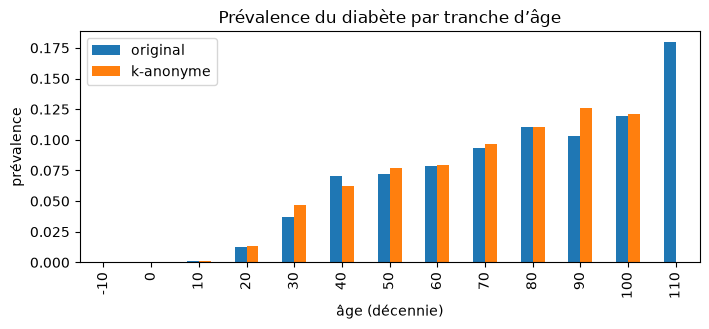

In [11]:
import matplotlib.pyplot as plt

age_orig = (2020 - pd.to_datetime(publication['BIRTHDATE']).dt.year) // 10 * 10
age_anon = (2020 - anonyme['BIRTHDATE'].str[:4].astype(int) - 5) // 10 * 10     # milieu de la tranche
prev = pd.DataFrame({
    'original': publication.groupby(age_orig)['DIAGNOSTIC'].apply(lambda d: (d == 'Diabetes').mean()),
    'k-anonyme': anonyme.groupby(age_anon)['DIAGNOSTIC'].apply(lambda d: (d == 'Diabetes').mean()),
})
prev.plot(kind='bar', figsize=(8, 3), title='Prévalence du diabète par tranche d’âge', xlabel='âge (décennie)', ylabel='prévalence');

**👀 Ce qu'on doit voir :** les **statistiques grossières** (prévalence par décennie d'âge) survivent presque intactes. Ce qui disparaît, c'est la **finesse** : la géographie passe de quelques centaines de codes postaux à une poignée de régions, l'âge à une dizaine de tranches.
Ici : 290 codes postaux deviennent 19 régions, 5 155 dates de naissance deviennent 12 tranches, 209 patients disparaissent. C'est le compromis permanent : plus k est grand, moins l'attaque marche, mais moins le fichier sert.

## Étape 6 : Limite du k-anonymat, la l-diversité
**Ce qu'on fait :** le k-anonymat cache **qui** est qui, pas **ce qu'il a**. Si les 5 membres d'une classe ont le même diagnostic, savoir qu'une personne est dans cette classe suffit (attaque d'**homogénéité**, Machanavajjhala *et al.*, 2006).
On compte les classes où tous les patients **malades** partagent le même diagnostic sensible, et les classes avec un seul diagnostic au total (l = 1).

In [12]:
classes = anonyme.groupby(QI)['DIAGNOSTIC']
diversite = classes.nunique()
print('Classes :', len(diversite), '| classes 1-diverses (un seul diagnostic) :', (diversite == 1).sum())
homogenes = classes.agg(lambda d: d.nunique() == 1 and d.iloc[0] != 'Aucun')
print('Classes où TOUS ont le même diagnostic sensible :', homogenes.sum())
anonyme.set_index(QI).loc[homogenes[homogenes].index]

Classes : 315 | classes 1-diverses (un seul diagnostic) : 37
Classes où TOUS ont le même diagnostic sensible : 1


DIAGNOSTIC
ZIP   BIRTHDATE GENDER                                
014** 1920-1929 F       Miscarriage in first trimester
                F       Miscarriage in first trimester
                F       Miscarriage in first trimester
                F       Miscarriage in first trimester
                F       Miscarriage in first trimester

**👀 Ce qu'on doit voir :** 37 classes sur 315 sont **1-diverses**. La plupart sont « Aucun » (peu grave), mais **une** classe ne contient que des patients avec le même diagnostic sensible : pour ses membres, connaître la région, la décennie de naissance et le sexe suffit à connaître le diagnostic, malgré k = 5.
La **l-diversité** exige au moins l valeurs sensibles « bien représentées » par classe ; elle a à son tour ses limites (t-proximité, attaques par connaissances externes). La vraie réponse à ces surenchères est une garantie mathématique : la **confidentialité différentielle** (exercice 5).

## Ce qu'il faut retenir
- Retirer nom et NAS ne suffit pas : {code postal, date de naissance, sexe} rend presque tout le monde unique, et une simple **jointure** ré-identifie les patients avec leur diagnostic.
- Le **k-anonymat** (généraliser + supprimer) bloque l'attaque de liaison : au mieux 1 chance sur k de deviner la bonne ligne.
- Le prix : géographie et âge beaucoup plus grossiers, quelques lignes supprimées. Les grandes tendances survivent, le détail non.
- Le k-anonymat ne protège pas l'**attribut sensible** (homogénéité) : d'où la l-diversité, puis la confidentialité différentielle.

**Exercice suivant :** on ne publie plus les données, on publie un **modèle**. Peut-on deviner qui était dans ses données d'entraînement ?